# RGB Renk Segmentasyonu — Omar

Görüntü BGR okunur, RGB uzayına dönüştürülür ve `cv2.inRange` ile sabit aralıktaki pikseller seçilir.
Aralık **yalnızca G1/G2'de** seçilip dondurulmuştur; K1–K4 sonucu görüldükten sonra değiştirilmez.
- Maske alanı (%) = 100 × seçilen piksel / toplam piksel
- Baş örtüşmesi (%) = baş ROI içindeki seçili piksel oranı → dört sınıflı karar

In [1]:
from pathlib import Path
import sys
KOK = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "kaynak" / "analiz.py").is_file())
sys.path.insert(0, str(KOK))

import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from kaynak.veri import ayarlari_oku, veri_setini_oku, goruntu_oku, maske_oku
from kaynak.analiz import analiz_et
from kaynak.gorsel import bgr2rgb, kutulari_ciz, maske_bindir
ayarlar = ayarlari_oku()
kayitlar = veri_setini_oku()
pd.set_option("display.max_colwidth", 80)
print("Görüntüler:", ", ".join(f"{k['kimlik']} ({k['bolum']})" for k in kayitlar))

Görüntüler: G1 (gelistirme), G2 (gelistirme), K1 (kontrol), K2 (kontrol), K3 (kontrol), K4 (kontrol)


## 1. Dondurulmuş ayarlar ve karar kuralı

In [2]:
print("RGB aralığı:", ayarlar["renk_araliklari"]["RGB"])
print("Karar kuralı:", ayarlar["karar_kurali"]["kural"])

RGB aralığı: {'alt': [180, 140, 0], 'ust': [255, 255, 120], 'gerekce': "Ekibin ortak başlangıç RGB aralığı. G1'deki baret piksellerinin (etiketler/kalibrasyon/G1_baret_firca.png)  %84.9'unu yakalıyor; renkli piksellerin %58.4'ü baret. G2'de seçilen alan %0."}
Karar kuralı: 1) Baş görünmüyorsa (bas_roi yok): belirsiz. 2) Görüntüdeki renkli alan < %2.5: baret_yok. 3) Baş bölgesindeki renkli piksel oranı >= %5: basta_baret. 4) Aksi halde: baret_var_basta_degil. Renk maskesi baret nesnesini kanıtlamaz; kural yalnızca renk ve konuma bakar.


## 2. Deney öncesi tahmin

In [3]:
tahminler = pd.read_csv(KOK / "belgeler/tahminler.csv")
benim = tahminler[(tahminler.uye == "Omar")]
if benim.empty:
    print("UYARI: Bu deney için kayıtlı tahmin yok. Hoca: 'Tahmini olmayan deney puanlanmaz.'")
    print("Deneyi çalıştırmadan ÖNCE belgeler/tahminler.csv dosyasına iki cümle ekleyin.")
for _, t in benim.iterrows():
    print(f"[{t.kayit_tarihi}] {t.deney_kimligi}\n 1) {t.tahmin_1}\n 2) {t.tahmin_2}\n   ({t.durum})\n")

[2026-11-02T19:05:44+03:00] rgb_baseline
 1) I expect the RGB range to find the yellow helmets in K2 and K3 but to struggle with the small distant helmet and with the low light of the night image, because a fixed RGB range depends on brightness.
 2) I expect K4 to be wrongly called helmet_on_head or to be borderline, because the mask sees the yellow helmet in the hand, and K1 to come out uncertain because no head box exists.
   (üye tarafından yazıldı)



## 3. Geliştirme (G1, G2) — aralık seçimi yalnızca burada

In [4]:
def tablo(bolum):
    satirlar = []
    for k in veri_setini_oku(bolum):
        s = analiz_et(goruntu_oku(k["dosya"]), "RGB", ayarlar, k["bas_roi"], k["baret_kutulari"])
        satirlar.append({"Görüntü": k["kimlik"], "Koşul": k["kosul"], "Maske alanı (%)": round(s["alan_yuzde"], 2),
                         "Baş örtüşmesi (%)": None if s["ortusme_yuzde"] is None else round(s["ortusme_yuzde"], 2),
                         "Kuralın sınıfı": s["sinif"], "Doğru sınıf": k["dogru_sinif"],
                         "Doğru mu": s["sinif"] == k["dogru_sinif"]})
    return pd.DataFrame(satirlar)
tablo("gelistirme")

,Görüntü,Koşul,Maske alanı (%),Baş örtüşmesi (%),Kuralın sınıfı,Doğru sınıf,Doğru mu
0,G1,"Gün ışığı; sarı baret başta, yüz net görünür (normal ışık)",4.79,36.48,basta_baret,basta_baret,True
1,G2,"Gün ışığı; baş görünür, kumaş şapka, baret yok",0.00,0.00,baret_yok,baret_yok,True


## 4. Kontrol (K1–K4) — 4 maske ve dört sınıflı karar

In [5]:
kontrol = tablo("kontrol"); kontrol

,Görüntü,Koşul,Maske alanı (%),Baş örtüşmesi (%),Kuralın sınıfı,Doğru sınıf,Doğru mu
0,K1,"Loş, soğuk mavi iç mekân ışığı; sarı baret başta; sarı-yeşil reflektif yelek",0.40,6.08,baret_yok,basta_baret,False
1,K2,Uzak; küçük baş ve baret,0.03,17.74,baret_yok,basta_baret,False
2,K3,"Gün ışığı; başı açık işçi (kumaş şapka), sarı-turuncu iş makinesi (aynı renk...",2.65,0.00,baret_var_basta_degil,baret_yok,False
3,K4,"Gün ışığı; sarı baret elde, başı açık ve görünür",17.59,2.61,baret_var_basta_degil,baret_var_basta_degil,True


In [6]:
print(f"Sınıf doğruluğu: {kontrol['Doğru mu'].sum()}/{len(kontrol)}")

Sınıf doğruluğu: 1/4


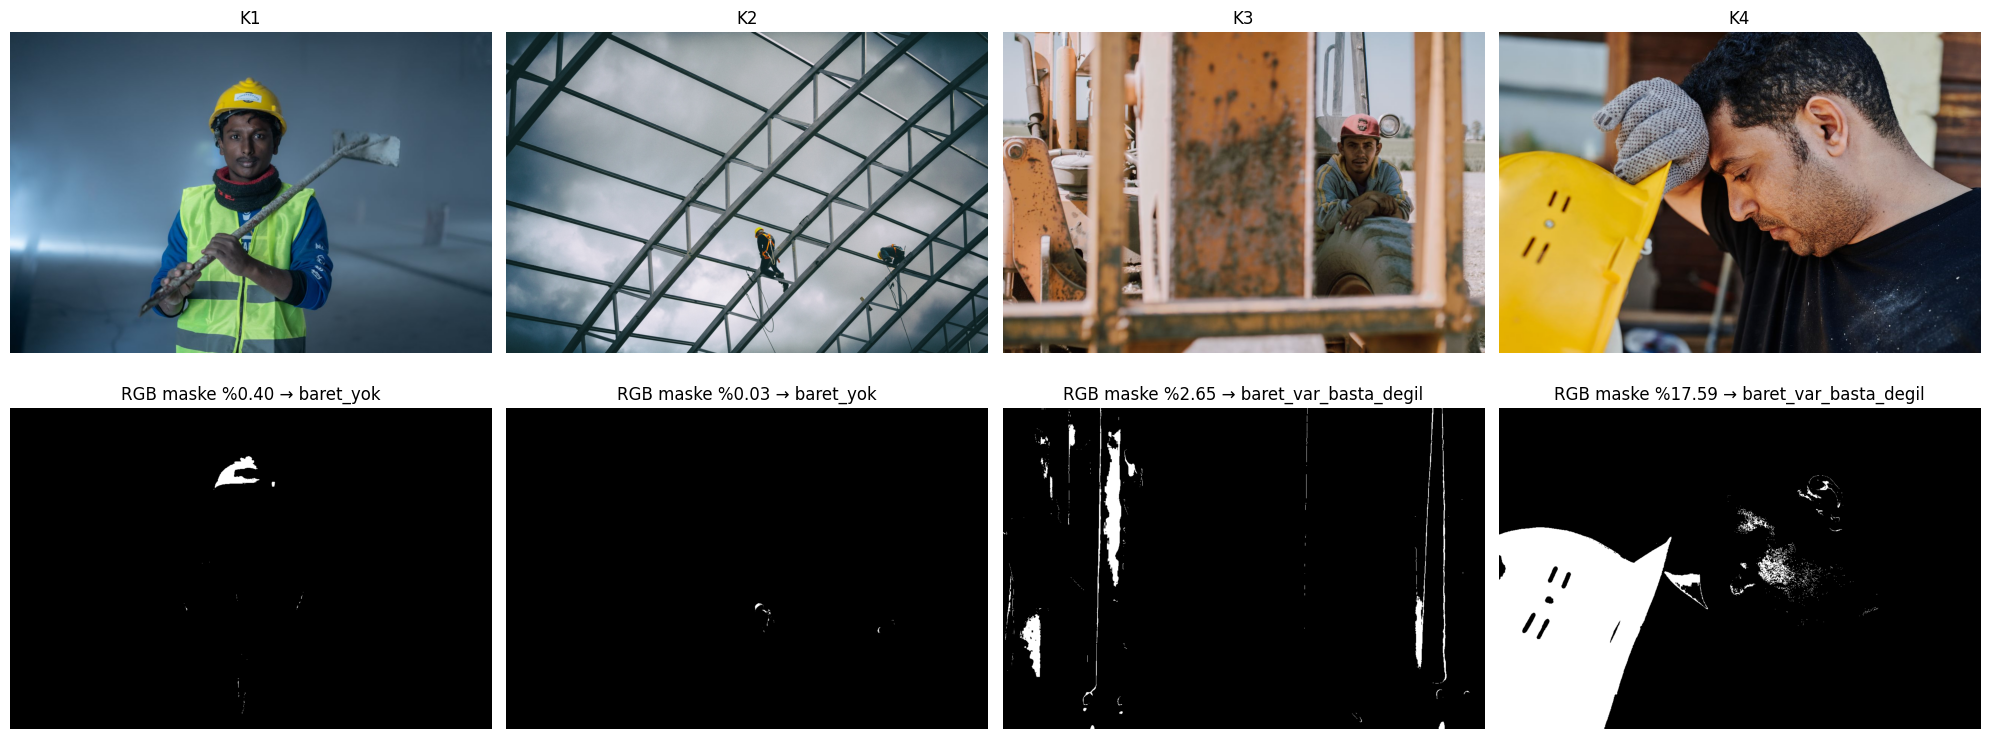

In [7]:
fig, eksen = plt.subplots(2, 4, figsize=(20, 8))
for i, k in enumerate(veri_setini_oku("kontrol")):
    g = goruntu_oku(k["dosya"]); s = analiz_et(g, "RGB", ayarlar, k["bas_roi"])
    eksen[0, i].imshow(bgr2rgb(g)); eksen[0, i].set_title(k["kimlik"])
    eksen[1, i].imshow(s["maske"], cmap="gray"); eksen[1, i].set_title(f"RGB maske %{s['alan_yuzde']:.2f} → {s['sinif']}")
    for e in eksen[:, i]: e.axis("off")
plt.tight_layout(); plt.show()

## Hata yorumu, sınırlılık ve sonraki kontrol
*(Üye kendi gözlemini yazar: gölge, düşük doygunluk, aynı renkli nesne; renk maskesi baret nesnesini kanıtlamaz.)*

**Tahminin tuttu mu?** Kısmen. Düşük ışık ve küçük/uzak baret yüzünden RGB'nin zorlanacağını yazmıştım; bu tuttu, çünkü loş K1'de ve uzak K2'de RGB "baret yok" dedi. K4 için yanlış sınıf bekliyordum ama kural doğru sınıfı verdi. K1'in "belirsiz" çıkacağını yazmıştım; yeni K1'de baş kutusu var, o yüzden bu kısım tutmadı. Tahminimi eski görüntülere göre yazmıştım ve sonradan değiştirmedim.

**Seçtiğim hata: K3.** Sarı-turuncu iş makinesi baret rengine çok yakın; maske alanı %2,65 olduğu için %2,5 eşiğini az farkla geçti ve kural "baret var, başta değil" dedi, oysa doğru sınıf "baret yok". Sonraki kontrol olarak alanı sadece baş çevresinde hesaplamayı veya şekil ölçütü (en–boy oranı, doluluk) eklemeyi G1/G2'de tanımlayıp K3'te bir kez ölçmek isterim.

**S1: Aynı baret gölgede neden RGB eşiğinin dışında kalır?** Gölgede baretin rengi aynı kalır ama parlaklığı düşer. RGB'de üç kanalın hepsi parlaklığa bağlı olduğu için kırmızı ve yeşil değerleri alt sınırın (180 ve 140) altına iner. İlk veri setinde gece görüntüsündeki baret pikselini yaklaşık RGB (92, 73, 9) ölçmüştüm; bu yüzden maske onu seçmedi. HSV'de parlaklık ayrı bir kanal (V) olduğu için bu sorun daha az olur.

**Önceki commit'i nasıl açıklarım?** Kendi RGB aralığımla K1–K4'ü görmüştüm; ondan sonra ekibin ortak ayarına geçtim ve sonuçları yeniden çalıştırdım (6eb5343). Bu doğru değildi, çünkü kontrol sonucunu gördükten sonra karar vermiş oldum ve arkadaşım benden bunu istememişti, bu yüzden geri aldım (3501c18). Şimdi kullanılan ortak aralık ve kural, kontrol çalıştırılmadan önce G1/G2'de seçilip donduruldu; K1–K4 sonucuna bakarak hiçbir eşiği değiştirmedim.

**Sınırlılık:** Renk maskesi baret nesnesini kanıtlamaz; K3'te baret olmayan sarı makine de seçildi, K1'de baretin sadece bir kısmı seçildi. Dört kontrol görüntüsü genel bir başarı iddiasını desteklemez.
